# Milestone 2 — SVD and Rank-k Approximation

Compute the SVD and compare reconstructions of different ranks.

In [2]:

import os

if not os.path.exists("/content/svd-image-compression"):
    !git clone -q https://github.com/billygoattrain/svd-image-compression.git /content/svd-image-compression

%cd /content/svd-image-compression


/content/svd-image-compression


In [3]:
import sys, pathlib
from skimage import data
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
# Works after downloading/extracting the package, or from the project root in Colab.
project_root = pathlib.Path.cwd()
if not (project_root / "src").exists() and (project_root.parent / "src").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))
from compress import rank_k_approx, storage, compression_ratio, rel_error, predicted_error, k_for_error
(project_root / "figures").mkdir(exist_ok=True)
photo_path = project_root / "data" / "my_photo.png"
if photo_path.exists():
    P = np.array(Image.open(photo_path).convert("L"), dtype=float)
else:
    P = None
    print("No personal photo yet: add data/my_photo.png before final submission.")

## SVD check

In [4]:
A=data.camera().astype(float)
U,s,Vt=np.linalg.svd(A,full_matrices=False)
print(U.shape,s.shape,Vt.shape)
print("Reconstruction close:",np.allclose((U*s)@Vt,A))
print("First singular values:",np.round(s[:5],1))

(512, 512) (512,) (512, 512)
Reconstruction close: True
First singular values: [70966.  17054.6 13314.9  8837.4  5874.6]


The SVD factors reconstruct the original image; the leading singular values dominate its energy.

## Singular values plot

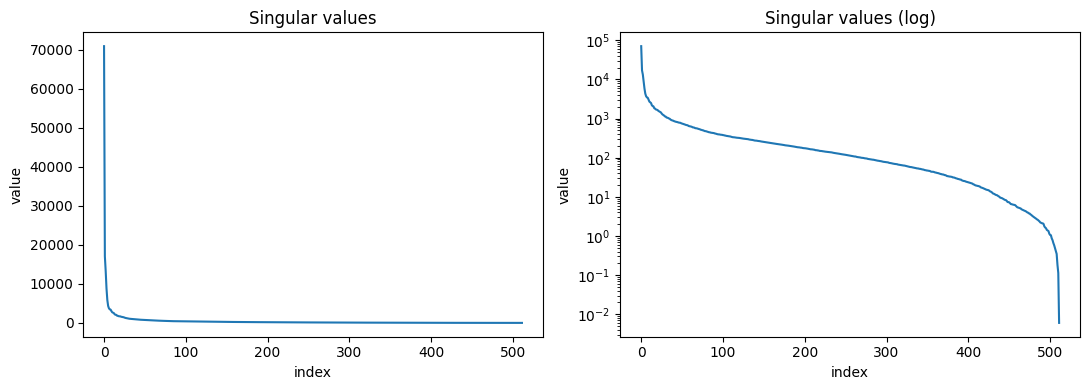

In [5]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].plot(s);axs[0].set(title="Singular values",xlabel="index",ylabel="value")
axs[1].semilogy(s);axs[1].set(title="Singular values (log)",xlabel="index",ylabel="value")
plt.tight_layout();plt.show()

The logarithmic scale reveals small singular values.

## Compare ranks

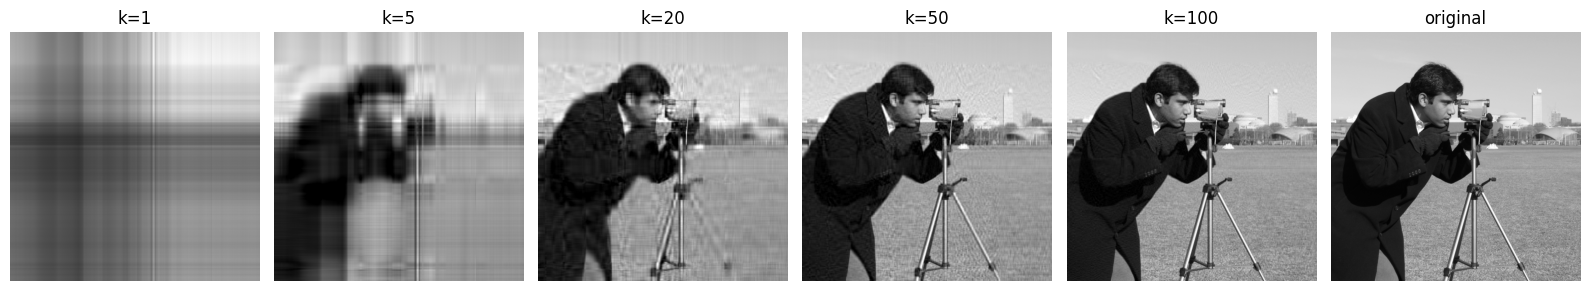

In [6]:
ks=[1,5,20,50,100]
fig,axs=plt.subplots(1,len(ks)+1,figsize=(16,3))
for ax,k in zip(axs,ks):
    ax.imshow(np.clip(rank_k_approx(A,k),0,255),cmap="gray",vmin=0,vmax=255)
    ax.set_title(f"k={k}");ax.axis("off")
axs[-1].imshow(A,cmap="gray",vmin=0,vmax=255);axs[-1].set_title("original");axs[-1].axis("off");plt.tight_layout();plt.show()

Smaller k uses fewer singular vectors but loses detail.

### What we found

The singular value decomposition successfully reconstructed the original 512 × 512 grayscale image, with Python confirming that the reconstruction was accurate. The largest singular value was approximately 70,966, which was significantly larger than the remaining values.

When comparing the rank-k approximations, I noticed that smaller ranks produced blurrier images, while larger ranks preserved more detail. At k = 1, the image was barely recognizable, but at k = 50 and k = 100, the image became much clearer and closer to the original.

This demonstrates that SVD can approximate an image using fewer singular values while maintaining much of its visual information.
